## This code is to plot the FTLE distributions of RC map trained on logistic map

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
import math

## The reservoir architecture

In [2]:
class ReservoirComputer:
    
    def __init__(self, dim_system, dim_reservoir, rho, sigma):
        
        self.dim_system = dim_system
        self.dim_reservoir = dim_reservoir
        self.r_state = np.zeros(dim_reservoir)                                   
        self.A = generate_adjacency_matrix(dim_reservoir, rho, sigma)

        
        self.W_in = W_inn(dim_reservoir, dim_system)
        self.W_b = W_bb(dim_reservoir)
        self.W_out = np.zeros((dim_system, dim_reservoir))
        
        

    
    def advance_r_state(self, eps, u):
        alpha = 0.86                                         
        self.r_state = ((1- alpha)* self.r_state) + alpha* np.tanh(np.matmul(self.A, self.r_state) + np.matmul(self.W_in, u.T) + self.W_b * (eps - 0.3))             # r_state is updated and stored as r(t+ delta t)
                                                                                    
        return self.r_state

    
    def train(self, trajectory_total, trajectory_new):                                                # Trajectory is the training data (initialized once model is called)
        
    
        R_total = np.empty((self.dim_reservoir, trajectory_total.shape[0]))
        eps_train = [3.92, 3.93, 3.94, 3.95]

        div = int((trajectory_total.shape[0])/len(eps_train))
        
        for m in range(len(eps_train)):

            self.r_state = np.zeros(self.dim_reservoir)
            
            for i in range(div*m , div + div*m):
                
                R_total[:, i] = self.r_state
                u = trajectory_total[i]                                                   # stores i th row by default
                self.advance_r_state(eps_train[m], u)

        range_removal = [(0,29),(1000,1029),(2000, 2029),(3000, 3029)]
        #range_removal = [(0,29)]
        column_removal = []
        for start, end in range_removal:
            column_removal.extend(range(start, end + 1))
        
        # Remove the specified columns
        R_total = np.delete(R_total, column_removal, axis=1)  #removing the r_state transient (first 10 elements)         
        
        
        self.W_out = linear_regression(R_total, trajectory_new)

        #print(self.W_out)                  

    def v(self):
        return np.transpose(np.matmul(self.W_out, self.r_state))                   # Gives the predicted output


    def predict(self, eps_new, steps, test_trajectory, train_trajectory):
        
        prediction = np.zeros((steps, self.dim_system))
        prediction[0] = test_trajectory[0,:]

        warmup = train_trajectory[0:30, :]                       # warmup of reservoir

        self.r_state = np.zeros(self.dim_reservoir)

        for l in range(30):

            self.advance_r_state(eps_new, warmup[l])

        self.r_warmup = self.r_state
        
        for i in range(steps-1):
            
            self.advance_r_state(eps_new, prediction[i])
            v = self.v()
            prediction[i+1] = v
            
        return prediction

    def get_weights(self):
        return self.A, self.W_in, self.W_out, self.W_b, self.r_warmup

In [3]:
def W_bb(dim_reservoir):

    np.random.seed(36)
    #W_b = (2* (np.random.rand(dim_reservoir)) - 0.5)* 1.15

    W_b = (2 * np.random.rand(dim_reservoir) - 1)* 1.15                     
    return W_b


def W_inn(dim_reservoir, dim_system):

    np.random.seed(85)
    W_in = 2 * 2.13 * (np.random.rand(dim_reservoir, dim_system) - 0.5)              
    return W_in

def generate_adjacency_matrix(dim_reservoir, rho, sigma):
    
    graph = nx.gnp_random_graph(dim_reservoir, sigma, seed = 47)                           # Generates an Erdos-Renyi graph of nodes = dim_reservoir and probab of node connection = sigma
    
    np.random.seed(27)
    nx.set_edge_attributes(graph, {e: {'weight': np.random.uniform(0, 1)} for e in graph.edges})    
    graph = nx.to_numpy_array(graph)

    rescaled = graph
    return scale_matrix(rescaled, rho)


def scale_matrix(A, rho):
    eigenvalues, _ = np.linalg.eig(A)
    max_eigenvalue = np.amax(eigenvalues)
    A = (A/np.absolute(max_eigenvalue)) * rho                 #this makes the spectral radius of matrix A as rho
    return A


In [4]:
def linear_regression(R, trajectory, beta=0.000001):
    Rt = np.transpose(R)
    inverse_part = np.linalg.inv(np.matmul(R, Rt) + beta * np.identity(R.shape[0]))                # Tikhonov Regularization
    return np.matmul(np.matmul(trajectory.T, Rt), inverse_part)                           

In [5]:
timesteps = 1100     

mu_list = [3.92, 3.93, 3.94, 3.95, 3.997]      

#mu_list = [3.92, 4.01]
data_list = []

# Initial conditions
for mu in mu_list:
    x0 = 0.3
    for j in range(timesteps):

        x0 = mu*x0*(1-x0)
   
        data_list.append(x0)
   
stacked_total = np.transpose(np.vstack(data_list))                                    
print(stacked_total.shape)

(1, 5500)


In [6]:
#train-test split

stacked_train = stacked_total[:, :-1100]
stacked_test = stacked_total[:, -1100:]
stacked_test = stacked_test[:, :1000]        


# removing transient of first 100 points each time
ranges_to_remove = [(0, 99), (1100, 1199), (2200, 2299), (3300,3399)]

#ranges_to_remove = [(0,99)]
columns_to_remove = []
for start, end in ranges_to_remove:
    columns_to_remove.extend(range(start, end + 1))


stacked_x_modified = np.delete(stacked_train, columns_to_remove, axis=1)
                 
training_data = np.transpose(stacked_x_modified)                

#print(training_data.shape)

# Remove the reservoir transient, 30 points each time
range_to_remove = [(0,29),(1000,1029),(2000, 2029),(3000, 3029)]

#range_to_remove = [(0,29)]
column_to_remove = []
for start, end in range_to_remove:
    column_to_remove.extend(range(start, end + 1))

# Remove the specified columns
train_without_transient = np.transpose(np.delete(stacked_x_modified, column_to_remove, axis=1))            
#print(train_without_transient.shape)
valid_data = np.transpose(stacked_test)          

In [7]:
dim_reservoir = 400                                                            
model = ReservoirComputer(1, dim_reservoir, 0.9, 0.526)                                    
model.train(training_data, train_without_transient)
predicted_data = model.predict(3.997 ,len(valid_data), valid_data, train_without_transient)          

## FTLE code for RC 

### Make the following changes to get different distributions:

1. **Typical chaos** : bif_param = 3.7, window_nn = 500, y_axis = log
2. **Fully developed chaos** : bif_param = 3.995, window_nn = 15, y_axis = normal
3. **Subduction (Intermittency)** : bif_param = 3.82744, window_nn = 300, y_axis = log
4. **Interior crisis** : bif_param = 3.856459, window_nn = 33, y_axis = log (also disable the comment setting the y-axis limit for a better visualisation)

In [14]:
from tqdm import tqdm
from scipy.stats import gaussian_kde

A, W_in, W_out, W_b, rstate_initial = model.get_weights()

# --- Parameters ---
Lambda = A + np.matmul(W_in, W_out)
Omega = W_b
alpha = 0.86

bif_param = 3.856459               
r_pert_size = 1e-6
t_warmm = 2000                  # warm-up to reach attractor
longg_T = 200000                # trajectory length
window_nn = 33                 # FTLE window size

# --- Define the reservoir map ---
def res_map(rstate, bif_param):
    return (1 - alpha) * rstate + alpha * np.tanh(Lambda @ rstate + Omega * (bif_param - 0.3))

# --- Initialize and warm-up the reservoir state ---
rstate = rstate_initial.copy()
for _ in range(t_warmm):
    rstate = res_map(rstate, bif_param)

# --- Preallocate trajectory and one-step stretch exponents ---
r_traj = np.empty((longg_T, len(rstate)))
stretch_logs = np.empty(longg_T)

# --- Initialize perturbation ---
r_pert = np.random.randn(*rstate.shape)
r_pert /= np.linalg.norm(r_pert)
r_pert *= r_pert_size

# --- Main simulation ---
for t in tqdm(range(longg_T), desc="Evolving reservoir"):
    # Save state
    r_traj[t] = rstate

    # Map forward
    r_next = res_map(rstate, bif_param)
    r_pert_next = res_map(rstate + r_pert, bif_param) - r_next

    # Compute instantaneous expansion (logarithmic stretch)
    norm = np.linalg.norm(r_pert_next)
    stretch_logs[t] = np.log(norm / r_pert_size)

    # Renormalize perturbation (Bennetin step)
    r_pert = (r_pert_next / norm) * r_pert_size

    # Update state
    rstate = r_next

# --- Compute moving average FTLEs (windowed mean) ---
ftless = np.convolve(stretch_logs, np.ones(window_nn), mode='valid') / window_nn
ftless = ftless[:longg_T]  # same length as main trajectory


Evolving reservoir: 100%|█████████████| 200000/200000 [00:36<00:00, 5489.77it/s]


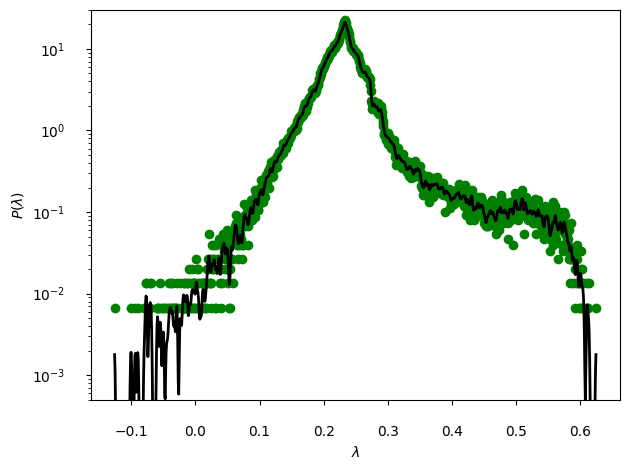

In [16]:
# --- Build and plot FTLE distribution ---
countss, bin_edgess = np.histogram(ftless, bins=1000, density=True)
bin_centerss = 0.5 * (bin_edgess[:-1] + bin_edgess[1:])
kde = gaussian_kde(ftless, bw_method = 0.02)
xgrid = np.linspace(bin_centerss.min(), bin_centerss.max(), 1000)

plt.plot(bin_centerss, countss, 'o', markersize=6, label='Histogram points', color = 'green')
plt.plot(xgrid, kde(xgrid), '-', lw=2, label='KDE', color = 'black')

plt.yscale('log')  # log scale on y-axis
plt.xlabel(r'$\lambda$')

plt.tick_params(axis='x', pad=15)
plt.tick_params(axis='y', pad=15)
plt.ylabel(r'$P(\lambda)$')


#plt.ylim(0.0005, 30)                       #disable the comment for interior crisis only
plt.tight_layout()

plt.show()